Libraries imported successfully!

Upload your cleaned healthcare Excel file:


Saving cleaned_healthcare_data (1).xlsx to cleaned_healthcare_data (1) (1).xlsx

Dataset loaded successfully!

First 5 records:
   Age  Gender   BMI  Smoking  Glucose   BP  Cholesterol  Disease
0   52       1  28.5        1      130  140        220.0        1
1   61       0  32.1        0      210  150        260.0        2
2   48       0  24.3        1       98  120        190.0        3
3   45       1  27.8        0      110  130        210.0        1
4   58       0  27.8        1      130  135        240.0        2

Dataset Shape: (15, 8)

Column Names: ['Age', 'Gender', 'BMI', 'Smoking', 'Glucose', 'BP', 'Cholesterol', 'Disease']

Missing Values:
Age            0
Gender         0
BMI            0
Smoking        0
Glucose        0
BP             0
Cholesterol    0
Disease        0
dtype: int64

Prepared Dataset Shape: (15, 8)

Disease Category Counts:
Disease
1    5
2    4
3    4
0    2
Name: count, dtype: int64
Training records: 11
Testing records: 4
Training categories: 4
Testing 

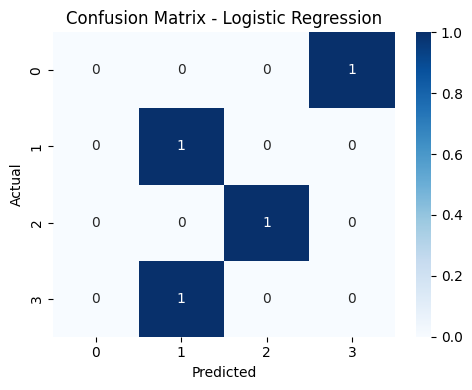


Decision Tree
Accuracy: 0.5
Precision: 0.3333
Recall: 0.5
F1 Score: 0.375

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         1
           1       0.33      1.00      0.50         1
           2       0.00      0.00      0.00         1
           3       0.00      0.00      0.00         1

    accuracy                           0.50         4
   macro avg       0.33      0.50      0.38         4
weighted avg       0.33      0.50      0.38         4



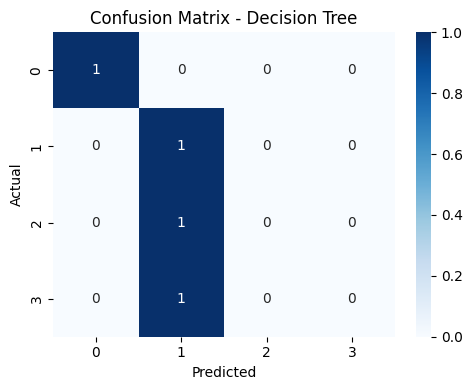


Random Forest
Accuracy: 0.25
Precision: 0.0833
Recall: 0.25
F1 Score: 0.125

Classification Report:
              precision    recall  f1-score   support

           0       0.00      0.00      0.00         1
           1       0.33      1.00      0.50         1
           2       0.00      0.00      0.00         1
           3       0.00      0.00      0.00         1

    accuracy                           0.25         4
   macro avg       0.08      0.25      0.12         4
weighted avg       0.08      0.25      0.12         4



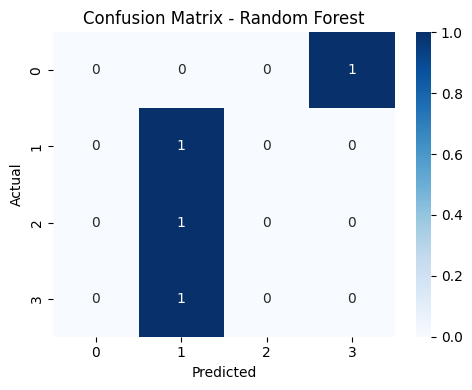


MODEL COMPARISON
              Model  Accuracy  Precision  Recall  F1 Score
Logistic Regression      0.50     0.3750    0.50    0.4167
      Decision Tree      0.50     0.3333    0.50    0.3750
      Random Forest      0.25     0.0833    0.25    0.1250

Best model on this test split: Logistic Regression
Based on macro F1 score.
This is a preliminary result, not clinical validation.


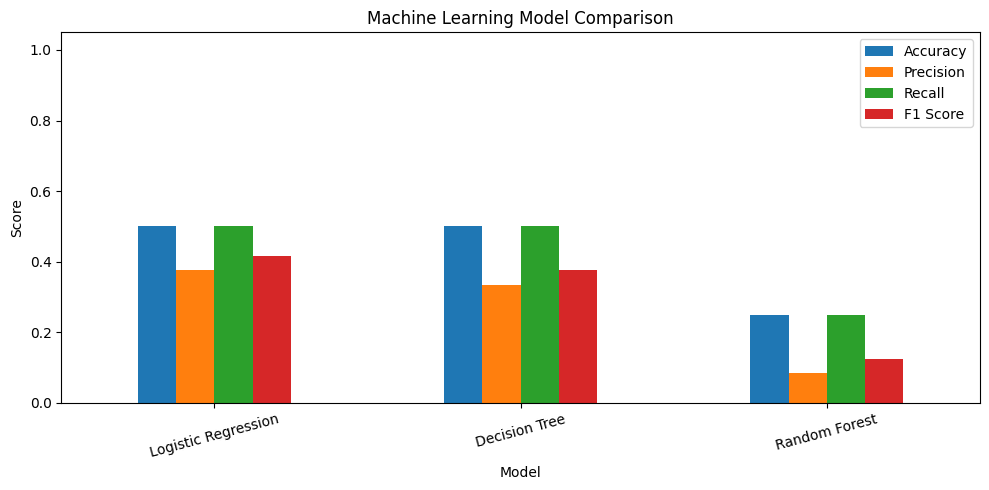


Feature Importance - Decision Tree
BP             0.666667
Cholesterol    0.333333
Age            0.000000
BMI            0.000000
Gender         0.000000
Glucose        0.000000
Smoking        0.000000
dtype: float64


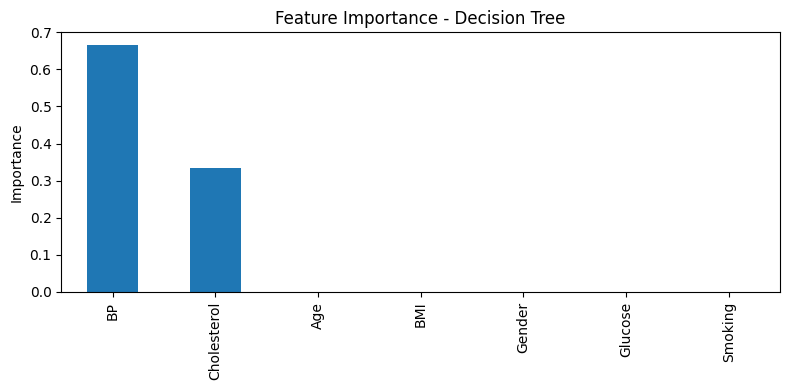


Feature Importance - Random Forest
BP             0.257700
BMI            0.209715
Glucose        0.199312
Age            0.155590
Cholesterol    0.131702
Gender         0.024006
Smoking        0.021976
dtype: float64


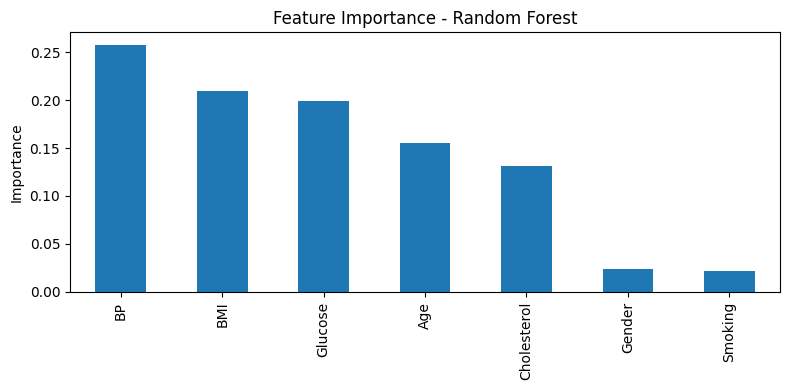


PROJECT COMPLETED
Dataset records used: 15
Input features: ['Age', 'Gender', 'BMI', 'Smoking', 'Glucose', 'BP', 'Cholesterol']
Target variable: Disease
Models trained: 3

Final Comparison:
              Model  Accuracy  Precision  Recall  F1 Score
Logistic Regression      0.50     0.3750    0.50    0.4167
      Decision Tree      0.50     0.3333    0.50    0.3750
      Random Forest      0.25     0.0833    0.25    0.1250

NOTE: The dataset contains only a small number of records. The metrics may be unstable and must not be used for medical diagnosis or treatment decisions.


In [ ]:

# HEALTHCARE DATA ANALYSIS AND DISEASE RISK PREDICTION

# 1. Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report
)

print("Libraries imported successfully!")

# 2. Upload Excel Dataset
print("\nUpload your cleaned healthcare Excel file:")
uploaded = files.upload()

file_path = next(iter(uploaded.keys()))
df = pd.read_excel(file_path)

# 3. Clean Column Names
df.columns = df.columns.astype(str).str.strip()

print("\nDataset loaded successfully!")
print("\nFirst 5 records:")
print(df.head())

print("\nDataset Shape:", df.shape)
print("\nColumn Names:", df.columns.tolist())
print("\nMissing Values:")
print(df.isnull().sum())

# 4. Validate Required Columns
target = "Disease"

features = [
    "Age", "Gender", "BMI", "Smoking",
    "Glucose", "BP", "Cholesterol"
]

required = features + [target]
missing_columns = [c for c in required if c not in df.columns]

if missing_columns:
    raise ValueError(
        f"Missing columns: {missing_columns}. "
        f"Available columns: {df.columns.tolist()}"
    )

# 5. Data Preparation
df = df.dropna(subset=[target]).copy()

# Convert feature columns to numeric
for col in features:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Remove rows where all feature values are missing
df = df.dropna(subset=features, how="all")

X = df[features]
y = df[target]

print("\nPrepared Dataset Shape:", df.shape)
print("\nDisease Category Counts:")
print(y.value_counts())

if y.nunique() < 2:
    raise ValueError(
        "At least two Disease categories are needed for classification."
    )


# 6. Train-Test Split (Fixed)

class_counts = y.value_counts()
number_of_classes = y.nunique()

# Ensure the test set can hold at least one record per class
test_records = max(
    int(np.ceil(0.20 * len(y))),
    number_of_classes
)

# Ensure enough records remain for training
if test_records >= len(y):
    raise ValueError(
        "Dataset is too small for a train-test split. "
        "Add more records to the dataset."
    )

stratify_y = (
    y if class_counts.min() >= 2 else None
)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=test_records,
    random_state=42,
    stratify=stratify_y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Training categories:", y_train.nunique())
print("Testing categories:", y_test.nunique())

# 7. Create Three Machine Learning Models
models = {
    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            max_iter=2000, class_weight="balanced"
        ))
    ]),

    "Decision Tree": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", DecisionTreeClassifier(
            max_depth=3,
            random_state=42,
            class_weight="balanced"
        ))
    ]),

    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(
            n_estimators=100,
            max_depth=3,
            random_state=42,
            class_weight="balanced"
        ))
    ])
}

# 8. Train and Evaluate Models
results = []
trained_models = {}

for name, model in models.items():
    print("\n" + "=" * 50)
    print(name)

    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    trained_models[name] = model

    accuracy = accuracy_score(y_test, predictions)
    precision = precision_score(
        y_test, predictions,
        average="macro", zero_division=0
    )
    recall = recall_score(
        y_test, predictions,
        average="macro", zero_division=0
    )
    f1 = f1_score(
        y_test, predictions,
        average="macro", zero_division=0
    )

    results.append({
        "Model": name,
        "Accuracy": round(accuracy, 4),
        "Precision": round(precision, 4),
        "Recall": round(recall, 4),
        "F1 Score": round(f1, 4)
    })

    print("Accuracy:", round(accuracy, 4))
    print("Precision:", round(precision, 4))
    print("Recall:", round(recall, 4))
    print("F1 Score:", round(f1, 4))

    print("\nClassification Report:")
    print(classification_report(
        y_test, predictions, zero_division=0
    ))

    # Confusion Matrix
    cm = confusion_matrix(
        y_test, predictions, labels=np.unique(y)
    )

    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
    plt.title(f"Confusion Matrix - {name}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.tight_layout()
    plt.show()

# 9. Compare All Models
comparison = pd.DataFrame(results)
comparison = comparison.sort_values(
    by="F1 Score", ascending=False
)

print("\nMODEL COMPARISON")
print(comparison.to_string(index=False))

# 10. Display Best Model on This Test Split
best_model_name = comparison.iloc[0]["Model"]

print("\nBest model on this test split:", best_model_name)
print("Based on macro F1 score.")
print("This is a preliminary result, not clinical validation.")

# 11. Model Comparison Graph
comparison.plot(
    x="Model",
    y=["Accuracy", "Precision", "Recall", "F1 Score"],
    kind="bar",
    figsize=(10, 5)
)

plt.title("Machine Learning Model Comparison")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

# 12. Feature Importance (Decision Tree and Random Forest)
for name in ["Decision Tree", "Random Forest"]:
    fitted_pipeline = trained_models[name]
    classifier = fitted_pipeline.named_steps["model"]

    importance = pd.Series(
        classifier.feature_importances_,
        index=features
    ).sort_values(ascending=False)

    print(f"\nFeature Importance - {name}")
    print(importance)

    importance.plot(
        kind="bar",
        figsize=(8, 4),
        title=f"Feature Importance - {name}"
    )
    plt.ylabel("Importance")
    plt.tight_layout()
    plt.show()

# 13. Final Summary
print("\nPROJECT COMPLETED")
print("Dataset records used:", len(df))
print("Input features:", features)
print("Target variable:", target)
print("Models trained:", len(trained_models))
print("\nFinal Comparison:")
print(comparison.to_string(index=False))

print(
    "\nNOTE: The dataset contains only a small number of records. "
    "The metrics may be unstable and must not be used for medical "
    "diagnosis or treatment decisions."
)
